In [ ]:
%%writefile requirements.txt
mediapipe>=0.10.30
opencv-contrib-python>=4.8
numpy>=1.24
matplotlib>=3.7

Writing requirements.txt


In [ ]:
!pip install -q -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 13.8 MB/s eta 0:00:00


In [ ]:
import os
import urllib.request

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
from mediapipe.tasks.python import BaseOptions, vision

# Landmark model file (downloaded automatically the first time)
MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/face_landmarker.task"
)
MODEL_PATH = os.path.join("models", "face_landmarker.task")
OUTPUT_DIR = "outputs"
MAX_FACES = 10            # most faces to detect in one image

# Drawing colors (BGR order, as OpenCV expects)
GREEN = (0, 255, 0)       # landmark points
RED = (0, 0, 255)         # face bounding box
MAGENTA = (255, 0, 255)   # lip overlay
CYAN = (255, 255, 0)      # face-skin contour


def _landmark_indices(connections):
    """Collect the unique landmark indices used by a MediaPipe connection set."""
    return sorted({c.start for c in connections} | {c.end for c in connections})


# Landmark indices that outline the face and the lips on the face mesh
FACE_OVAL_IDX = _landmark_indices(vision.FaceLandmarksConnections.FACE_LANDMARKS_FACE_OVAL)
LIPS_IDX = _landmark_indices(vision.FaceLandmarksConnections.FACE_LANDMARKS_LIPS)

def load_image(path, max_width=800):
    """read the image and resize it

def preprocess(img):
    """Apply basic image operations.(smooth, equalized)

In [ ]:
def load_image(path, max_width=800):
    img = cv2.imread(path)
    if img is None:
        print(f"Could not read image: {path}")
        return None
    h, w = img.shape[:2]
    if w > max_width:
        scale = max_width / w
        img = cv2.resize(img, (max_width, int(h * scale)), interpolation=cv2.INTER_AREA)
    return img


def preprocess(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    equalized = cv2.equalizeHist(gray)
    smoothed = cv2.GaussianBlur(img, (5, 5), 0)
    return smoothed, equalized

In [ ]:
def ensure_model(path=MODEL_PATH):
    """Download the Face Landmarker model file the first time it is needed."""
    if os.path.exists(path):
        return
    os.makedirs(os.path.dirname(path), exist_ok=True)
    print("Downloading face landmark model (one time only)...")
    try:
        urllib.request.urlretrieve(MODEL_URL, path)
    except Exception as error:
        if os.path.exists(path):
            os.remove(path)
        raise RuntimeError(f"Could not download the model: {error}")
    print("Model saved to", path)


def detect_landmarks(img):
    """Topic (f): return a list of (N, 2) float arrays of landmark pixel positions, one per face."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # MediaPipe expects RGB
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

    options = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=MODEL_PATH),
        num_faces=MAX_FACES,
    )
    with vision.FaceLandmarker.create_from_options(options) as landmarker:
        result = landmarker.detect(mp_image)

    h, w = img.shape[:2]
    faces = []
    for face in result.face_landmarks:
        # MediaPipe gives coordinates in the range 0-1; convert to pixels
        points = np.array([[lm.x * w, lm.y * h] for lm in face], dtype=np.float32)
        faces.append(points)
    return faces


def bounding_box(points, img_shape):
    """Bounding box (x1, y1, x2, y2) around one face's landmarks, kept inside the image."""
    h, w = img_shape[:2]
    x1, y1 = np.floor(points.min(axis=0)).astype(int)
    x2, y2 = np.ceil(points.max(axis=0)).astype(int)
    return max(x1, 0), max(y1, 0), min(x2, w - 1), min(y2, h - 1)

def segment(smoothed, faces):
    """segment skin, the face region, and the lips.

In [ ]:
def segment(smoothed, faces):
    """Topic (b): segment skin, the face region, and the lips.

    The final face-skin mask = skin mask AND face region, so the landmarks
    guide the segmentation.
    """
    h, w = smoothed.shape[:2]

    ycrcb = cv2.cvtColor(smoothed, cv2.COLOR_BGR2YCrCb)
    skin = cv2.inRange(ycrcb, np.array([0, 133, 77]), np.array([255, 173, 127]))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    skin = cv2.morphologyEx(skin, cv2.MORPH_OPEN, kernel)                 # remove specks
    skin = cv2.morphologyEx(skin, cv2.MORPH_CLOSE, kernel, iterations=2)  # fill holes

    face_region = np.zeros((h, w), np.uint8)
    lips = np.zeros((h, w), np.uint8)
    for points in faces:
        oval = points[FACE_OVAL_IDX].astype(np.int32)
        cv2.fillConvexPoly(face_region, cv2.convexHull(oval), 255)
        lip_points = points[LIPS_IDX].astype(np.int32)
        cv2.fillConvexPoly(lips, cv2.convexHull(lip_points), 255)

    face_skin = cv2.bitwise_and(skin, face_region)
    segmented = cv2.bitwise_and(smoothed, smoothed, mask=face_skin)
    contours, _ = cv2.findContours(face_skin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return {
        "skin": skin,
        "face_region": face_region,
        "face_skin": face_skin,
        "lips": lips,
        "segmented": segmented,
        "contours": contours,
    }

In [ ]:
def draw_results(img, faces, seg):
    """Draw the lip overlay, contours, bounding boxes, labels, and landmark points."""
    out = img.copy()

    # Semi-transparent overlay on the lips mask
    tint = np.zeros_like(out)
    tint[:] = MAGENTA
    blended = cv2.addWeighted(out, 0.5, tint, 0.5, 0)
    lips_area = seg["lips"] > 0
    out[lips_area] = blended[lips_area]

    cv2.drawContours(out, seg["contours"], -1, CYAN, 1)

    for i, points in enumerate(faces, start=1):
        x1, y1, x2, y2 = bounding_box(points, img.shape)
        cv2.rectangle(out, (x1, y1), (x2, y2), RED, 2)
        cv2.putText(out, f"Face {i}", (x1, max(y1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, RED, 2)
        for x, y in points:
            cv2.circle(out, (int(x), int(y)), 1, GREEN, -1)
    return out


def show_panel(img, equalized, seg, annotated, save_path, display=True):
    """Build a 2x3 figure showing every stage of the pipeline."""
    rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    panels = [
        ("1. Original", rgb(img), None),
        ("2. Grayscale + histogram equalization", equalized, "gray"),
        ("3. Skin mask (YCrCb + morphology)", seg["skin"], "gray"),
        ("4. Face region from landmarks", seg["face_region"], "gray"),
        ("5. Segmented face skin", rgb(seg["segmented"]), None),
        ("6. Final: box, label, landmarks, lips", rgb(annotated), None),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, (title, image, cmap) in zip(axes.ravel(), panels):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(save_path, dpi=150)
    print("Saved summary figure:", save_path)
    if display:
        plt.show()
    plt.close(fig)


def run_analysis(image_path, show=True):
    """Run the full pipeline on one image and save the results in outputs/."""
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    ensure_model()

    img = load_image(image_path)
    if img is None:
        return
    smoothed, equalized = preprocess(img)

    faces = detect_landmarks(img)
    if not faces:
        print("No face detected. Try a clearer, front-facing photo.")
        return
    print(f"Faces detected: {len(faces)}")
    for i, points in enumerate(faces, start=1):
        print(f"  Face {i}: {len(points)} landmark points")

    seg = segment(smoothed, faces)
    annotated = draw_results(img, faces, seg)

    base = os.path.splitext(os.path.basename(image_path))[0]
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"{base}_annotated.png"), annotated)
    show_panel(img, equalized, seg, annotated,
               os.path.join(OUTPUT_DIR, f"{base}_summary.png"),
               display=show)

In [ ]:
from google.colab import files
import shutil

os.makedirs("images", exist_ok=True)
uploaded = files.upload()          # choose your photos
for name in uploaded:
    if name.lower().endswith((".jpg", ".jpeg", ".png")):
        shutil.move(name, os.path.join("images", name))
print("Photos in images/:", sorted(os.listdir("images")))

Saving sample1.jpg to sample1.jpg
Saving sample2.jpg to sample2.jpg
Saving sample3.jpg to sample3.jpg
Photos in images/: ['sample1.jpg', 'sample2.jpg', 'sample3.jpg']


Model saved to models/face_landmarker.task
Faces detected: 1
  Face 1: 478 landmark points
Saved summary figure: outputs/sample1_summary.png


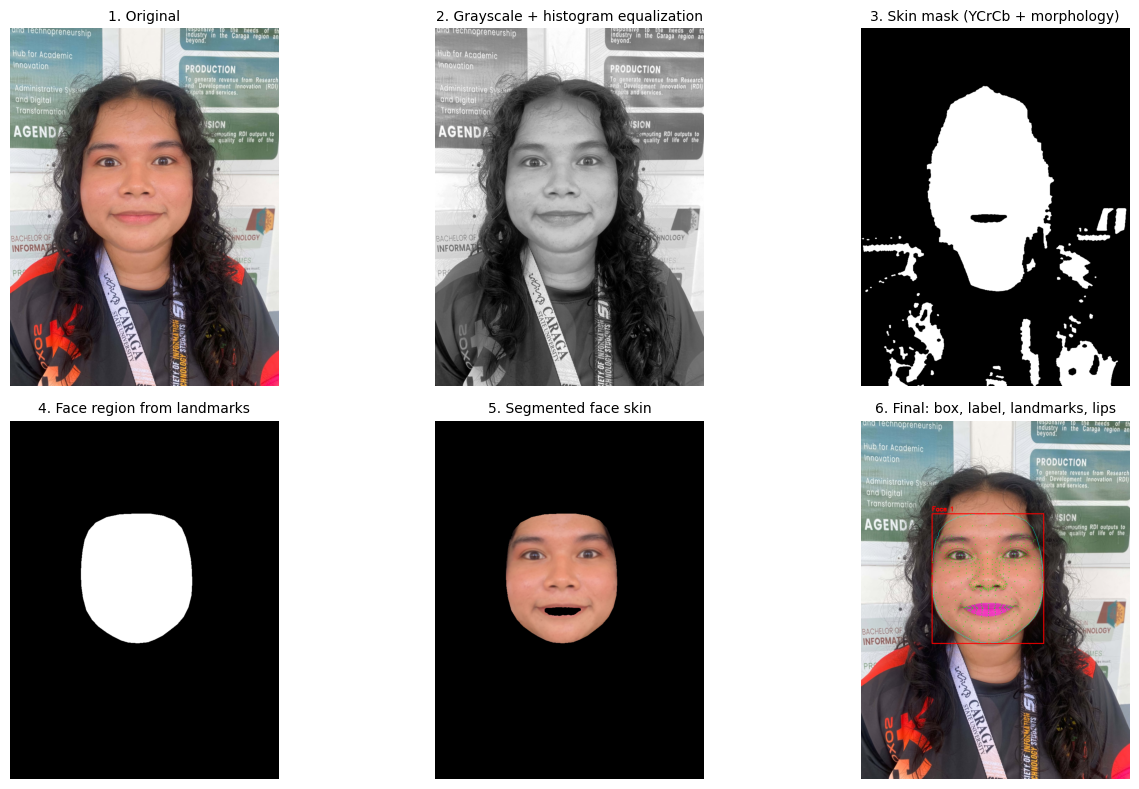

In [ ]:
IMAGE_PATH = "images/sample1.jpg"   # change to the name of one of your photos
run_analysis(IMAGE_PATH)

Faces detected: 2
  Face 1: 478 landmark points
  Face 2: 478 landmark points
Saved summary figure: outputs/sample2_summary.png


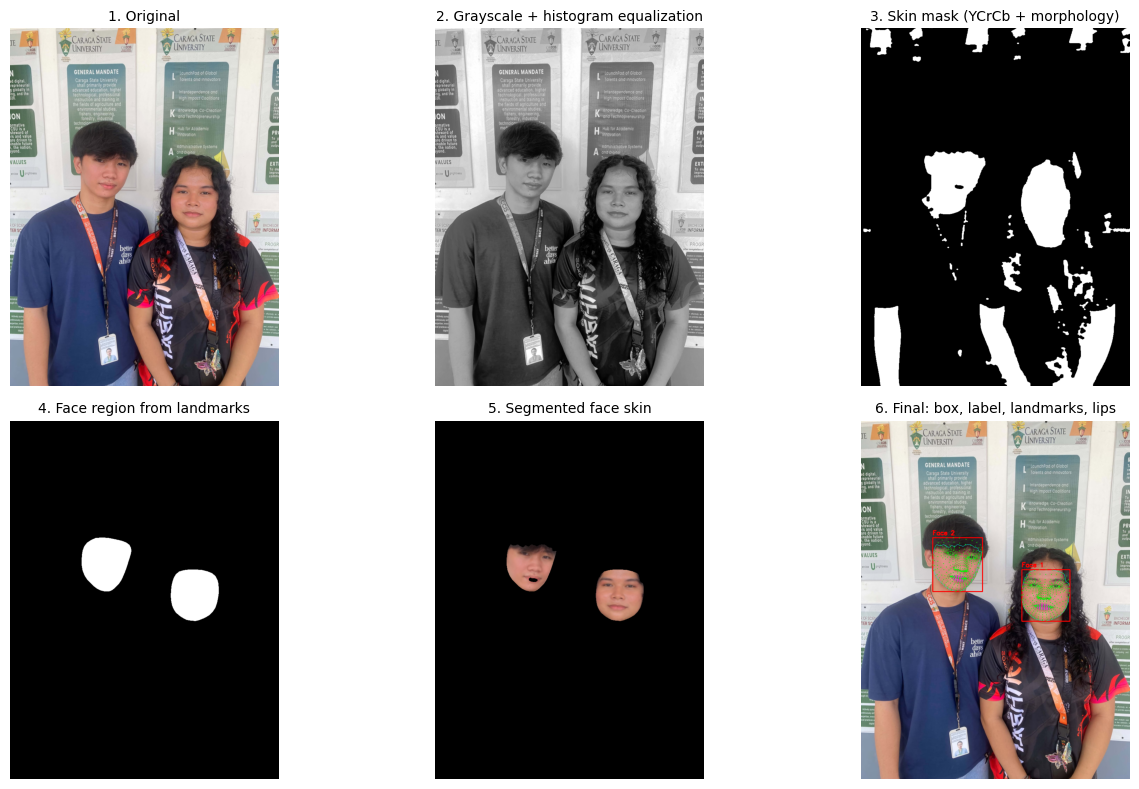

In [ ]:
IMAGE_PATH = "images/sample2.jpg"   # change to the name of one of your photos
run_analysis(IMAGE_PATH)

Faces detected: 3
  Face 1: 478 landmark points
  Face 2: 478 landmark points
  Face 3: 478 landmark points
Saved summary figure: outputs/sample3_summary.png


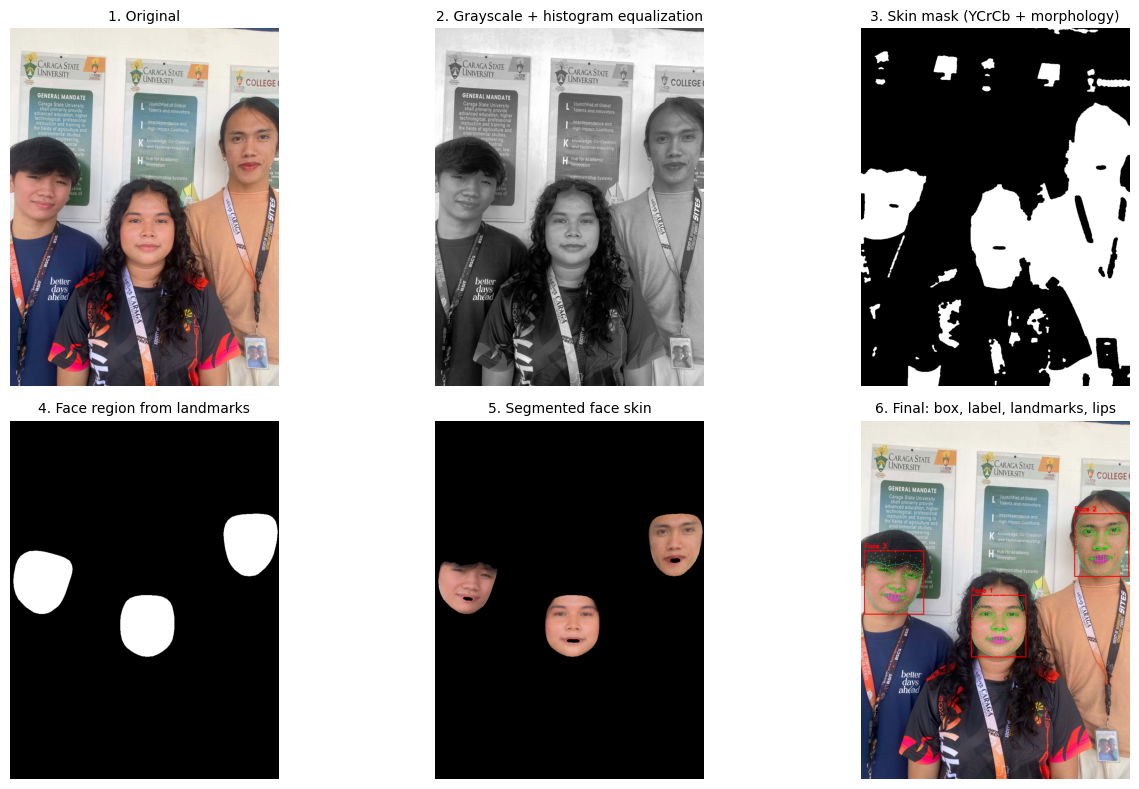

In [ ]:
IMAGE_PATH = "images/sample3.jpg"   # change to the name of one of your photos
run_analysis(IMAGE_PATH)